<font size = 6>Import libraries</font>

In [276]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_confusion_matrix
from sklearn.metrics import confusion_matrix
from PIL import Image


<font size = 6>Loading the data</font>

In [277]:

data_dir = "dataset"
img_size = (100, 100)
batch_size = 32

def load_dataset(split):
    ds = tf.keras.utils.image_dataset_from_directory(
        f"{data_dir}/{split}",
        image_size=img_size,
        color_mode="rgb",
        batch_size=batch_size,
        label_mode="int",
        class_names=[str(i) for i in range(10)],
        shuffle=(split == "train"),
        seed=42
    )

    images_list = []
    labels_list = []

    for images, labels in ds:
        images_list.append(images.numpy())
        labels_list.append(labels.numpy())

    x = np.concatenate(images_list, axis=0).astype(np.float32)
    y = np.concatenate(labels_list, axis=0).astype(np.int32)

    x /= 255.0

    return x, y


x_train, y_train = load_dataset("train")
x_valid, y_valid = load_dataset("valid")
x_test, y_test = load_dataset("test")


print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_valid:", x_valid.shape)
print("y_valid:", y_valid.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("Pixel range:", x_train.min(), x_train.max())
print("Classes:", np.unique(y_train))




Found 1712 files belonging to 10 classes.
Found 300 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
x_train: (1712, 100, 100, 3)
y_train: (1712,)
x_valid: (300, 100, 100, 3)
y_valid: (300,)
x_test: (50, 100, 100, 3)
y_test: (50,)
Pixel range: 0.0 1.0
Classes: [0 1 2 3 4 5 6 7 8 9]


<font size=6>Design The CNN Network</font>

<font size = 6>Data augmentation</font>

In [278]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomRotation(factor=0.02 , fill_mode="constant",fill_value=1.0),
    tf.keras.layers.RandomTranslation(width_factor=0.05 , height_factor=0.05 , fill_mode="constant",fill_value=1.0),
    tf.keras.layers.RandomZoom(height_factor=(-0.1, 0.1),width_factor=(-0.1, 0.1),fill_mode="constant",fill_value=1.0),
    tf.keras.layers.RandomContrast(factor=0.1),
    tf.keras.layers.GaussianNoise(stddev=0.01)

])

<font size = 6>Design architecture</font>

In [279]:

tf.keras.utils.clear_session()
tf.random.set_seed(42)

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=[100,100,3]),

    data_augmentation,

    tf.keras.layers.Conv2D(filters=16 , kernel_size=3 , activation="leaky_relu" , kernel_initializer="he_normal" , strides=1 , padding="same"),
    tf.keras.layers.MaxPool2D(pool_size=2 , strides=2), 
    tf.keras.layers.BatchNormalization(),   

    tf.keras.layers.Conv2D(filters=32 , kernel_size=3 , activation="leaky_relu" , kernel_initializer="he_normal" , strides=1 , padding="same"),
    tf.keras.layers.MaxPool2D(pool_size=2 , strides=2),  
    tf.keras.layers.BatchNormalization(),  

    tf.keras.layers.Conv2D(filters=64 , kernel_size=3 , activation="elu" , kernel_initializer="he_normal" , strides=2 , padding="same"),
    tf.keras.layers.BatchNormalization(), 
    tf.keras.layers.Conv2D(filters=64 , kernel_size=3 , activation="elu" , kernel_initializer="he_normal" , strides=1 , padding="same"),
    tf.keras.layers.MaxPool2D(pool_size=2 , strides=2),   
    tf.keras.layers.BatchNormalization(), 

    tf.keras.layers.Conv2D(filters=128 , kernel_size=3 , activation="leaky_relu" , kernel_initializer="he_normal" , strides=1 , padding="same"),
    tf.keras.layers.BatchNormalization(), 

    tf.keras.layers.Dropout(rate=0.4),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(512 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.Dropout(rate=0.4),

    # tf.keras.layers.Dense(256 , activation="leaky_relu" , kernel_initializer="he_normal"),
    # tf.keras.layers.Dropout(rate=0.3),

    tf.keras.layers.Dense(10 , activation="softmax")


])



<font size=6>Compile the model</font>

In [280]:
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy , metrics=["accuracy"] , optimizer=tf.keras.optimizers.SGD(learning_rate=0.001 , momentum=0.9))

<font size=6>Use Early Stopping</font>

In [281]:

def learning_rate(epoch):
    if epoch <= 5:
        return 0.01
    elif epoch > 5 and epoch <= 15:
        return 0.001
    elif epoch > 15 and epoch <= 25:
        return 0.0001
    elif epoch >25:
        return 0.00001

learning_rate_schedule = tf.keras.callbacks.LearningRateScheduler(schedule=learning_rate)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy" , mode="max" , patience=5 , restore_best_weights=True)

<font size=6>Train the model</font>

In [282]:
history = model.fit(x_train , y_train , epochs=40 , batch_size=32 , validation_data=(x_valid , y_valid) , callbacks=[learning_rate_schedule , early_stopping])

Epoch 1/40
 1/54 ━━━━━━━━━━━━━━━━━━━━ 1:16 1s/step - accuracy: 0.0625 - loss: 4.2228

E0000 00:00:1794151355.807471   11847 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.5362 - loss: 1.9245 - val_accuracy: 0.2300 - val_loss: 6.3641 - learning_rate: 0.0100
Epoch 2/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7593 - loss: 0.8633 - val_accuracy: 0.4333 - val_loss: 1.8827 - learning_rate: 0.0100
Epoch 3/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8353 - loss: 0.5601 - val_accuracy: 0.6800 - val_loss: 0.9636 - learning_rate: 0.0100
Epoch 4/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8732 - loss: 0.4554 - val_accuracy: 0.7367 - val_loss: 0.8138 - learning_rate: 0.0100
Epoch 5/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8890 - loss: 0.3826 - val_accuracy: 0.7467 - val_loss: 0.7994 - learning_rate: 0.0100
Epoch 6/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9206 - loss: 0.2904 - val_accuracy: 0.8900 - val_loss: 0.3617 - learning_rate: 0.0100
Epoch 7/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9030 - loss: 0.4003 - val_accuracy: 0.94

<font size=6>Evaluate model on test data</font>

In [283]:
print(f"Evaluate loss model on test data : {model.evaluate(x_test , y_test)[0]}")
print(f"Evaluate accuracy model on test data : {model.evaluate(x_test , y_test)[1]}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9800 - loss: 0.1038
Evaluate loss model on test data : 0.10380840301513672
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9800 - loss: 0.1038
Evaluate accuracy model on test data : 0.9800000190734863


<font size=6>Summary of model</font>

In [284]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 50, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 25, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 6, 6, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,000,438 (19.08 MB)

 Trainable params: 2,499,914 (9.54 MB)

 Non-trainable params: 608 (2.38 KB)

 Optimizer params: 2,499,916 (9.54 MB)

<font size=6>Plot learning curve of model</font>

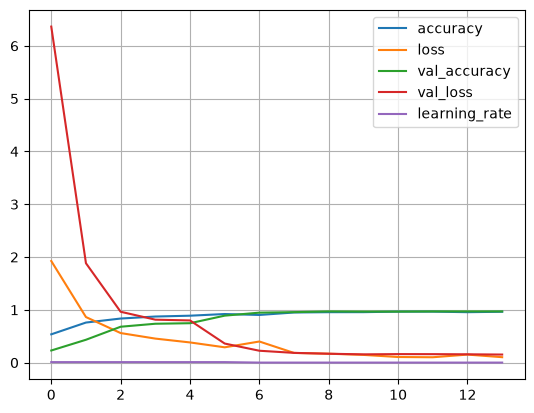

In [ ]:
plt.plot(pd.DataFrame(history.history) , label=history.history.keys())
plt.grid()
plt.legend()
# plt.savefig("learning_curve.jpg")

<font size=6>Plot confusion matrix on test data</font>

In [286]:

y_pred = np.argmax(model.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
cm


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


array([[5, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 5, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 5, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 5, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 5, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 5, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 5, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 4, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 5, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 5]])

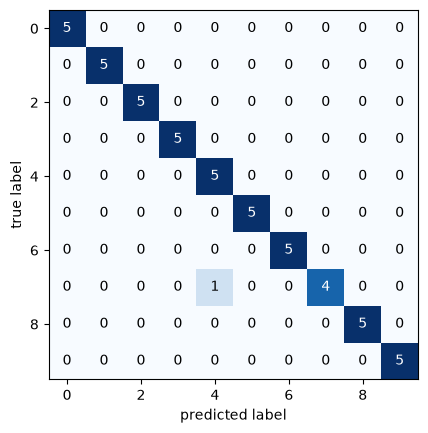

In [ ]:

plot_confusion_matrix(cm )
# plt.savefig("confusion_matrix.jpg")

<font size = 6>Evaluate model on real data (Outside the dataset's data)</font>

<font size = 5>Evaluate model on number 0</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
The predict of model is : [0]


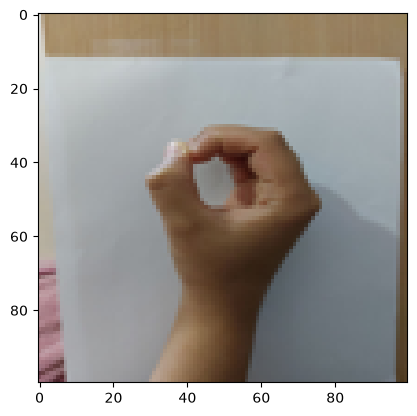

In [ ]:

img = Image.open("dataset/image0.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 1</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
The predict of model is : [1]


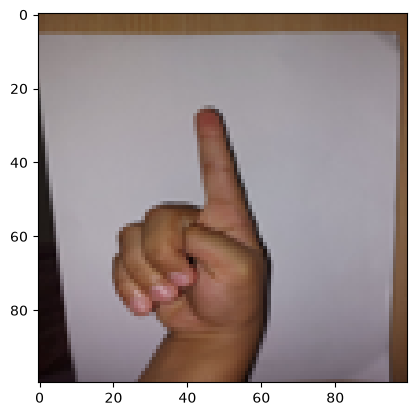

In [ ]:
img = Image.open("dataset/image1.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 2</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
The predict of model is : [2]


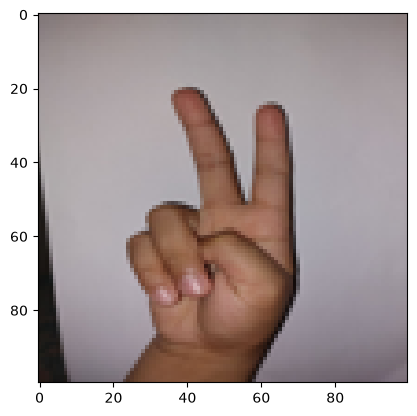

In [ ]:
img = Image.open("dataset/image2.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 3</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
The predict of model is : [3]


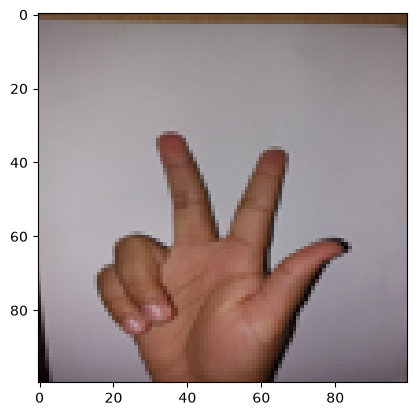

In [ ]:
img = Image.open("dataset/image3.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 4</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
The predict of model is : [4]


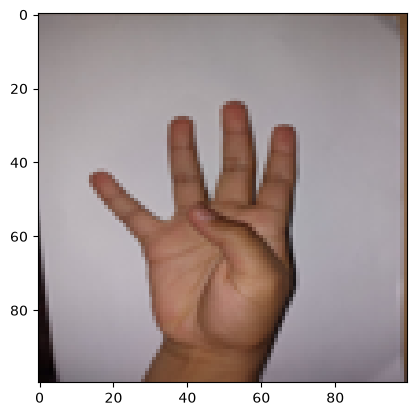

In [ ]:
img = Image.open("dataset/image4.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 5</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
The predict of model is : [5]


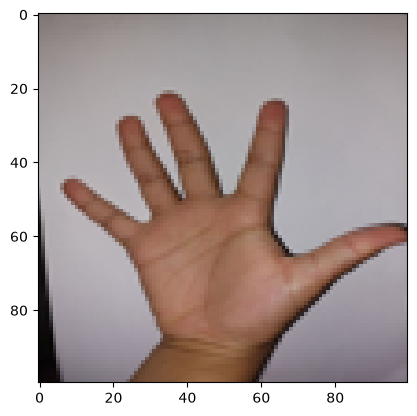

In [ ]:
img = Image.open("dataset/image5.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 6</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The predict of model is : [6]


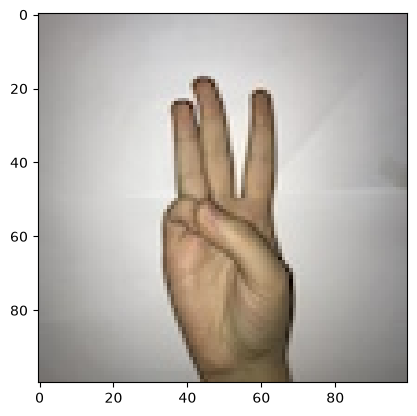

In [303]:
img = Image.open("dataset/image6.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 7</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
The predict of model is : [7]


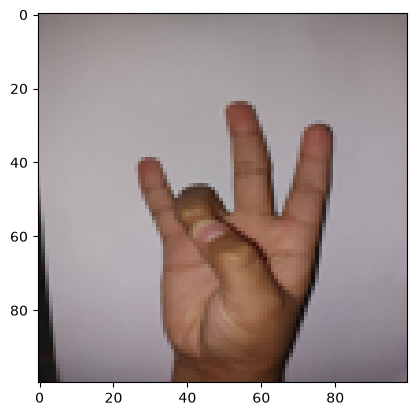

In [ ]:
img = Image.open("dataset/image7.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 8</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
The predict of model is : [8]


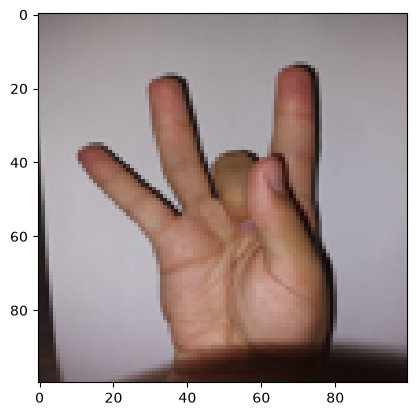

In [ ]:
img = Image.open("dataset/image8.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size = 5>Evaluate model on number 9</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is : [9]


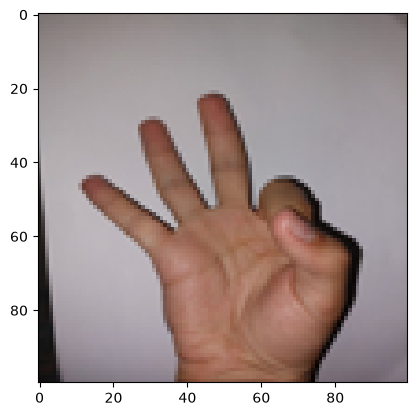

In [ ]:
img = Image.open("dataset/image9.jpg")
img = img.convert("RGB")
img = img.resize((100,100) , resample=Image.Resampling.LANCZOS)
img = np.array(img)/255.5

plt.imshow(img)
print(f"The predict of model is : {model.predict(img.reshape(1,100,100,3)).argmax(axis=1)}")

<font size=6>Save model</font>

In [306]:
model.save("model.keras")